In [49]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score, brier_score_loss
)
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42


In [50]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

### 1) Load Data + Normalize Column Names

* Kaggle datasets often come with inconsistent naming (Max HR, Chest pain type, etc.).
* We normalize names to snake_case, then auto-detect target.

In [51]:
import re

PATH = "/kaggle/input/heartdisease/Heart_Disease_Prediction.csv"  # adjust if needed
df = pd.read_csv(PATH)

def clean_col(c):
    c = c.strip().lower()
    c = re.sub(r"[^\w\s]", "", c)      # remove punctuation
    c = re.sub(r"\s+", "_", c)         # spaces -> underscore
    return c

df.columns = [clean_col(c) for c in df.columns]

df.head(), df.shape


(   age  sex  chest_pain_type   bp  cholesterol  fbs_over_120  ekg_results  \
 0   70    1                4  130          322             0            2   
 1   67    0                3  115          564             0            2   
 2   57    1                2  124          261             0            0   
 3   64    1                4  128          263             0            0   
 4   74    0                2  120          269             0            2   
 
    max_hr  exercise_angina  st_depression  slope_of_st  \
 0     109                0            2.4            2   
 1     160                0            1.6            2   
 2     141                0            0.3            1   
 3     105                1            0.2            2   
 4     121                1            0.2            1   
 
    number_of_vessels_fluro  thallium heart_disease  
 0                        3         3      Presence  
 1                        0         7       Absence  
 2          

## 2) Basic Sanity Checks (You skip this, your results are trash)

We check:
* Duplicates
* Missingness
* Type issues (numbers stored as strings)
* Target distribution (class imbalance)

In [52]:
print("Rows, Cols:", df.shape)
print("\nDuplicates:", df.duplicated().sum())

missing = df.isna().mean().sort_values(ascending=False)
display(pd.DataFrame({"missing_rate": missing, "missing_count": df.isna().sum()}))

df.info()


Rows, Cols: (270, 14)

Duplicates: 0


,missing_rate,missing_count
age,0.0,0
sex,0.0,0
chest_pain_type,0.0,0
bp,0.0,0
cholesterol,0.0,0
fbs_over_120,0.0,0
ekg_results,0.0,0
max_hr,0.0,0
exercise_angina,0.0,0
st_depression,0.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      270 non-null    int64  
 1   sex                      270 non-null    int64  
 2   chest_pain_type          270 non-null    int64  
 3   bp                       270 non-null    int64  
 4   cholesterol              270 non-null    int64  
 5   fbs_over_120             270 non-null    int64  
 6   ekg_results              270 non-null    int64  
 7   max_hr                   270 non-null    int64  
 8   exercise_angina          270 non-null    int64  
 9   st_depression            270 non-null    float64
 10  slope_of_st              270 non-null    int64  
 11  number_of_vessels_fluro  270 non-null    int64  
 12  thallium                 270 non-null    int64  
 13  heart_disease            270 non-null    object 
dtypes: float64(1), int64(12), 

In [53]:
# Try common target names
possible_targets = ["heartdisease", "heart_disease", "target", "label"]
target_col = None
for t in possible_targets:
    if t in df.columns:
        target_col = t
        break

if target_col is None:
    # fallback: last column if binary
    last = df.columns[-1]
    if df[last].nunique() == 2:
        target_col = last

print("Target column:", target_col)
df[target_col].value_counts(dropna=False)


Target column: heart_disease


heart_disease
Absence     150
Presence    120
Name: count, dtype: int64

## 3) Column Type Inference (Automatic)

We classify features into:
* numeric (continuous)
* binary (0/1)
* categorical (low-cardinality or object)

This matters because the right visualization depends on the type.

In [54]:
X_cols = [c for c in df.columns if c != target_col]

# Attempt numeric coercion for object columns
for c in X_cols:
    if df[c].dtype == "object":
        df[c] = pd.to_numeric(df[c], errors="ignore")

num_cols = []
cat_cols = []
bin_cols = []

for c in X_cols:
    nun = df[c].nunique(dropna=True)
    if pd.api.types.is_numeric_dtype(df[c]):
        if nun <= 2:
            bin_cols.append(c)
        else:
            num_cols.append(c)
    else:
        # object / category
        if nun <= 20:
            cat_cols.append(c)
        else:
            # high-cardinality text? treat as categorical but warn
            cat_cols.append(c)

print("Numeric:", num_cols)
print("Binary :", bin_cols)
print("Categorical:", cat_cols)


Numeric: ['age', 'chest_pain_type', 'bp', 'cholesterol', 'ekg_results', 'max_hr', 'st_depression', 'slope_of_st', 'number_of_vessels_fluro', 'thallium']
Binary : ['sex', 'fbs_over_120', 'exercise_angina']
Categorical: []


## 4) Data Quality: Outliers + Invalid Ranges

Medical data has plausible ranges. If your dataset has:
* cholesterol = 0
* BP = 0
* MaxHR insane values
…you need to flag them, not “plot and pray”.

In [55]:
def iqr_outlier_rate(s):
    s = s.dropna()
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ((s < lo) | (s > hi)).mean(), lo, hi

report = []
for c in num_cols:
    rate, lo, hi = iqr_outlier_rate(df[c])
    report.append([c, df[c].min(), df[c].max(), df[c].median(), rate, lo, hi])

qc = pd.DataFrame(report, columns=["col","min","max","median","iqr_outlier_rate","iqr_low","iqr_high"]) \
       .sort_values("iqr_outlier_rate", ascending=False)

display(qc)


,col,min,max,median,iqr_outlier_rate,iqr_low,iqr_high
1,chest_pain_type,1.0,4.0,3.0,0.074074,1.5,5.5
8,number_of_vessels_fluro,0.0,3.0,0.0,0.070370,-1.5,2.5
2,bp,94.0,200.0,130.0,0.033333,90.0,170.0
3,cholesterol,126.0,564.0,245.0,0.018519,112.5,380.5
6,st_depression,0.0,6.2,0.8,0.014815,-2.4,4.0
5,max_hr,71.0,202.0,153.5,0.003704,83.5,215.5
0,age,29.0,77.0,55.0,0.000000,28.5,80.5
4,ekg_results,0.0,2.0,2.0,0.000000,-3.0,5.0
7,slope_of_st,1.0,3.0,2.0,0.000000,-0.5,3.5
9,thallium,3.0,7.0,3.0,0.000000,-3.0,13.0


## 5) Univariate Visuals (Distribution Quality)
### Why these matter
* **Histogram + KDE:** tells you shape, skew, multimodality
* **Boxplot:** quick outlier + spread
* **Violin:** distribution density (better than box alone)
* **ECDF:** shows full cumulative distribution (hard to fake)
* **QQ plot:** checks normality (useful before parametric tests)

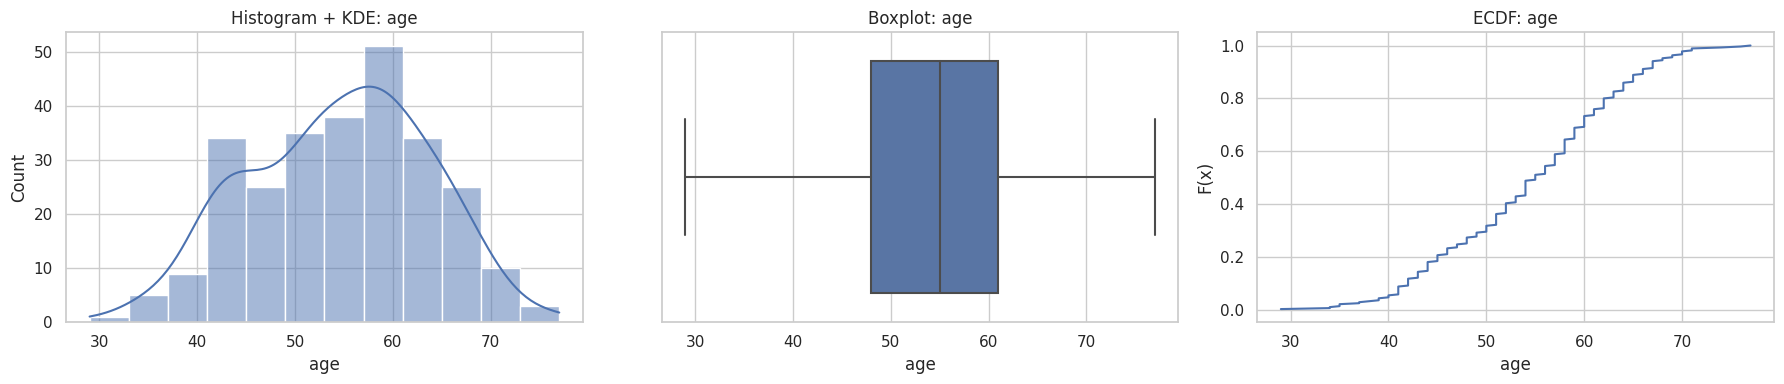

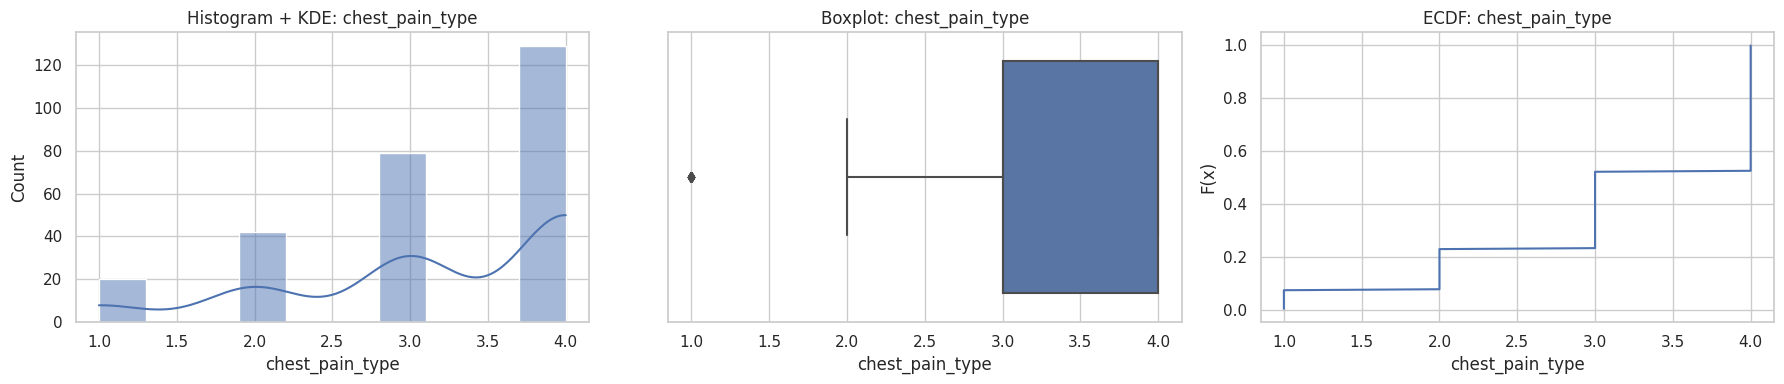

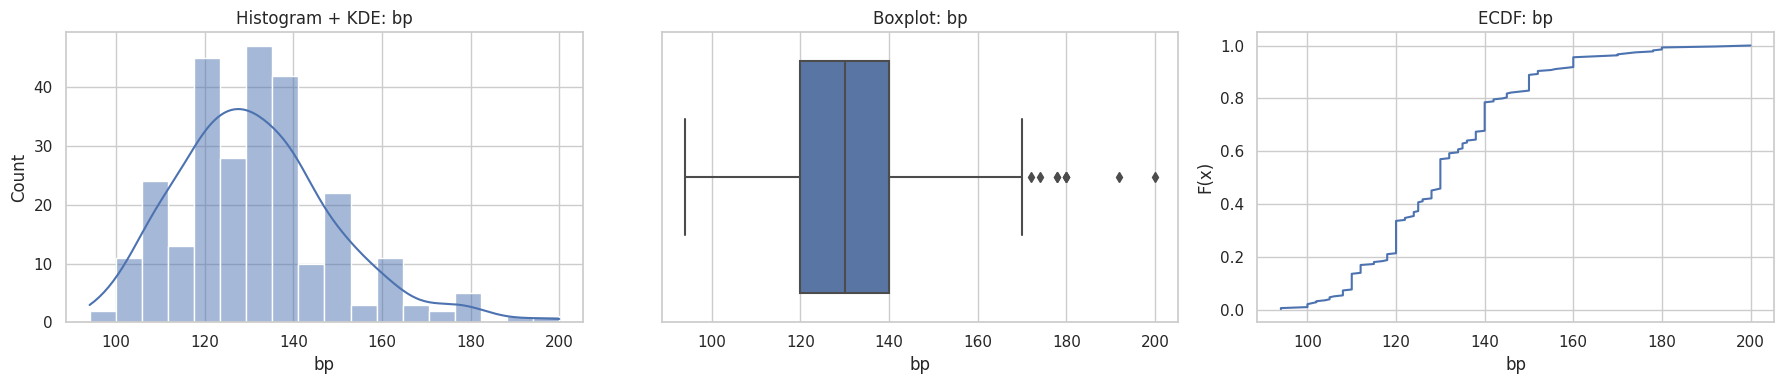

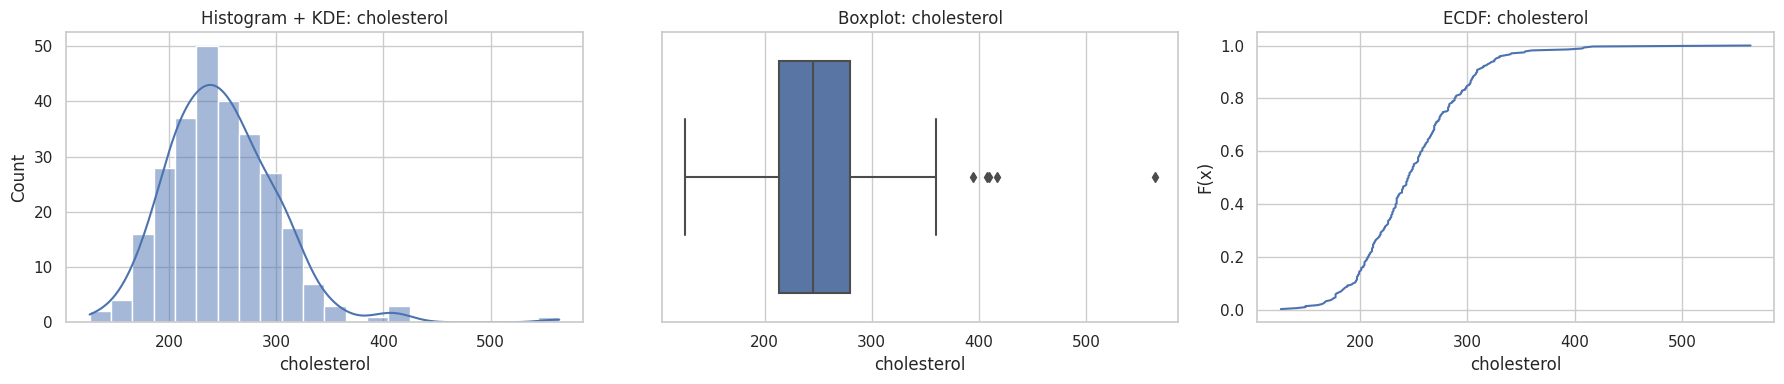

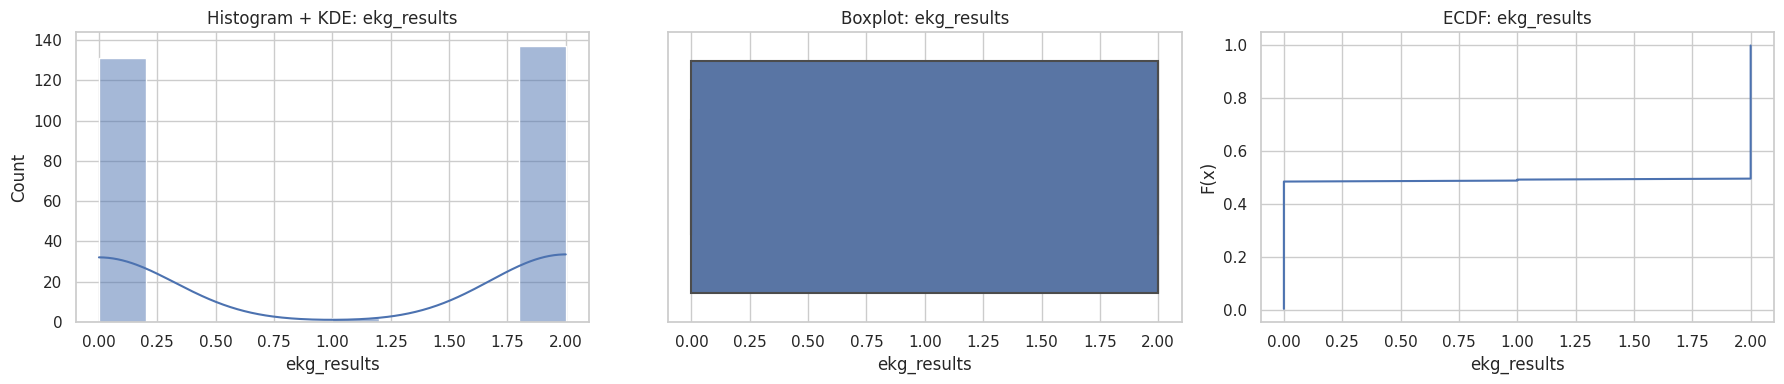

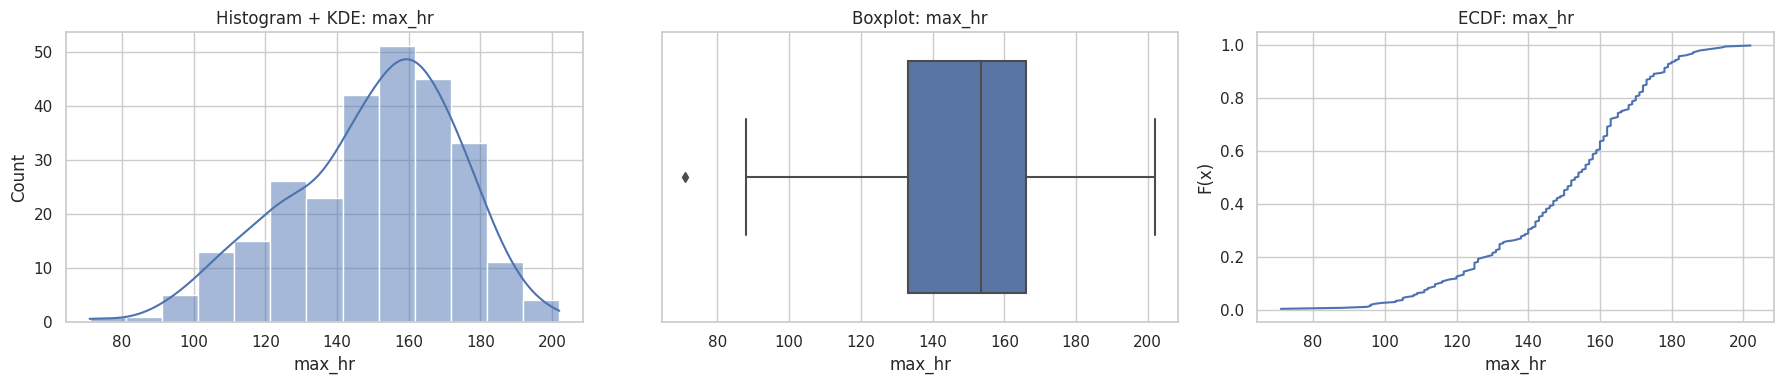

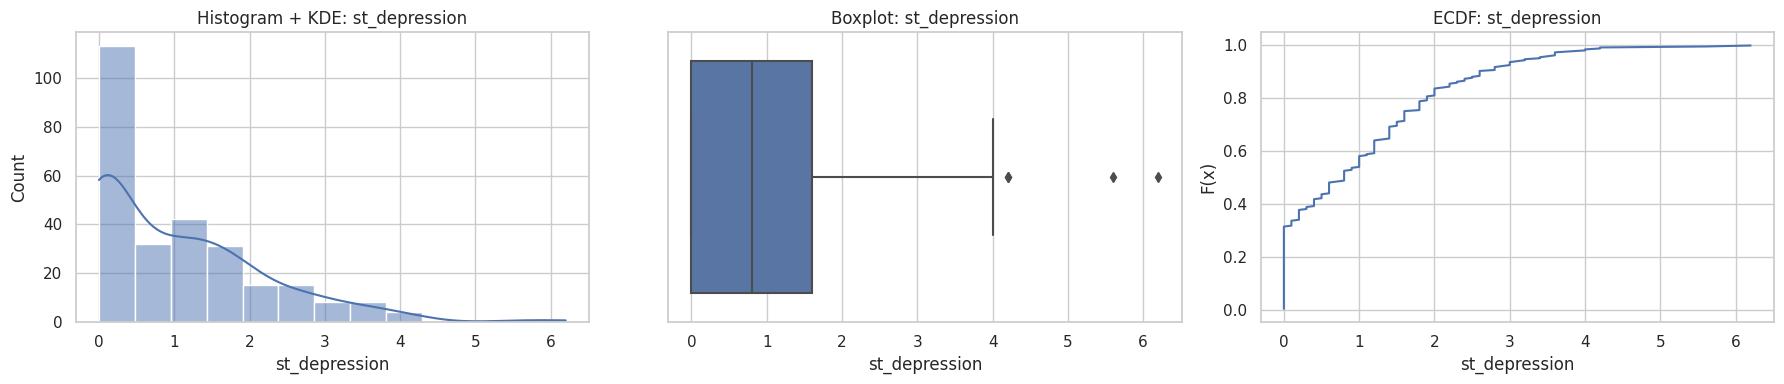

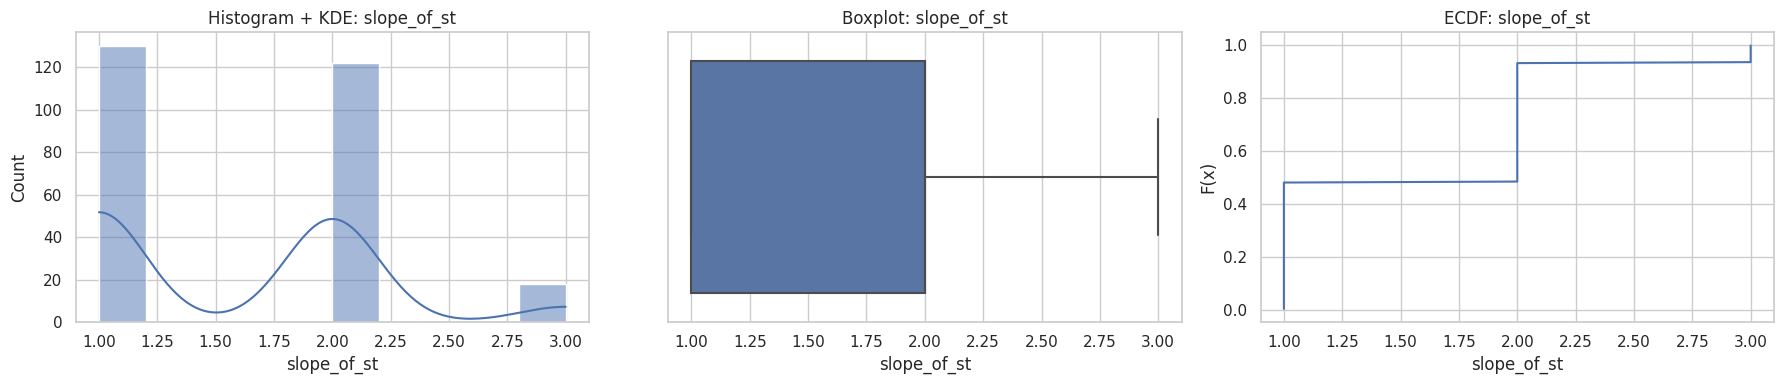

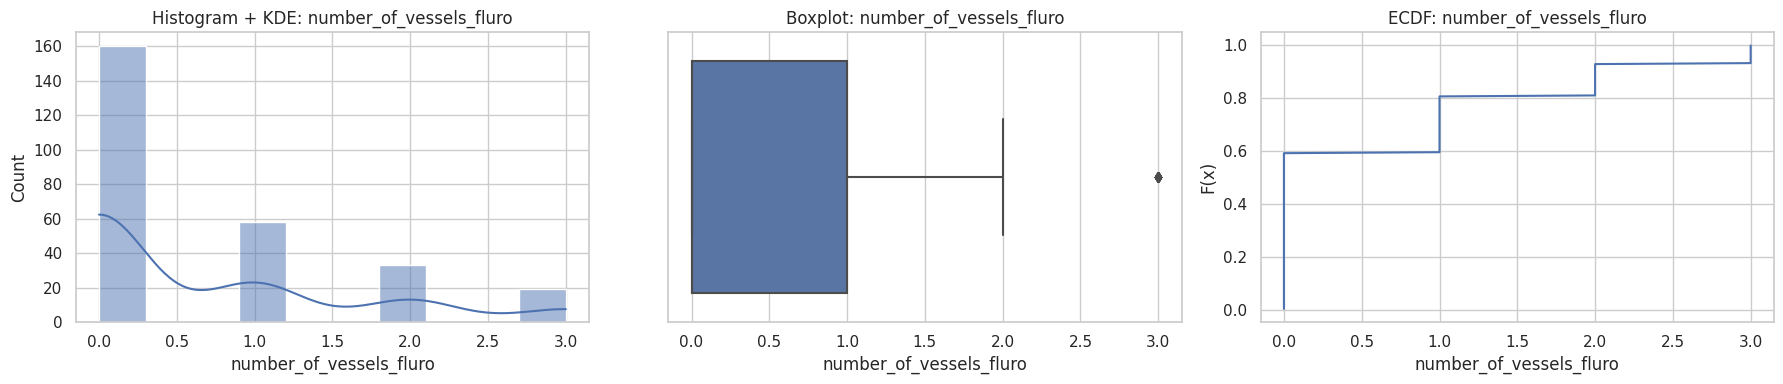

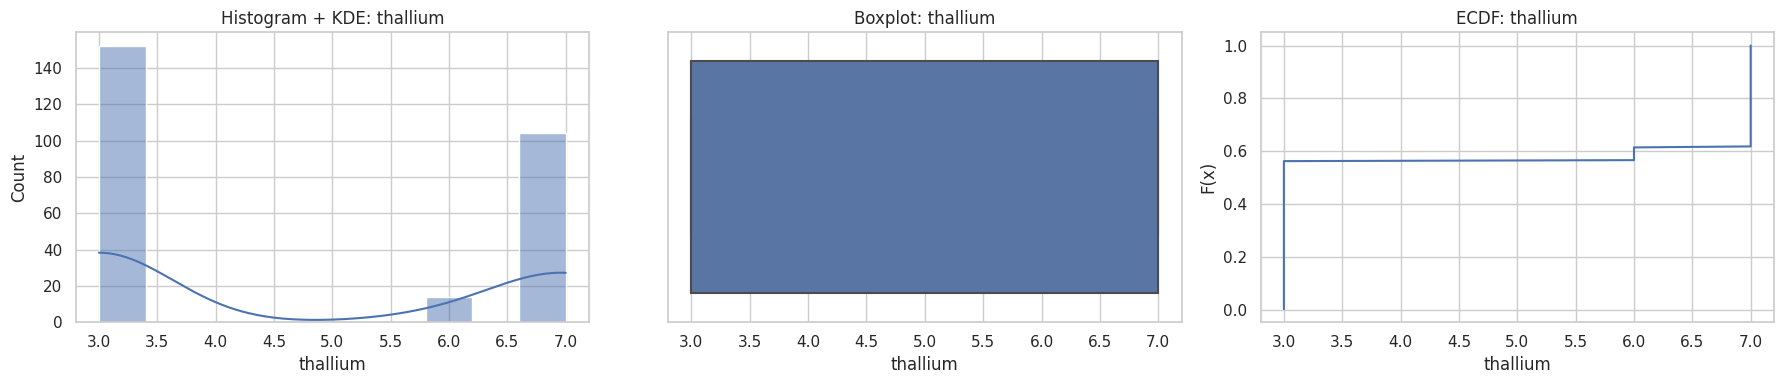

In [56]:
def plot_univariate_numeric(df, col):
    s = df[col].dropna()
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    
    sns.histplot(s, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram + KDE: {col}")
    
    sns.boxplot(x=s, ax=axes[1])
    axes[1].set_title(f"Boxplot: {col}")
    
    # ECDF
    x = np.sort(s)
    y = np.arange(1, len(x)+1) / len(x)
    axes[2].plot(x, y)
    axes[2].set_title(f"ECDF: {col}")
    axes[2].set_xlabel(col)
    axes[2].set_ylabel("F(x)")
    
    plt.tight_layout()
    plt.show()

for c in num_cols:
    plot_univariate_numeric(df, c)


# 6) Target-Stratified Visuals (What separates Disease vs No Disease?)

If you don’t stratify by target, your EDA is mostly useless.

## Best visuals by type

### Numeric vs target (binary)
* Box/violin + swarm (distribution + individual points)
* Ridge density plots (shape differences)
* Effect size plots (Cohen’s d / Cliff’s delta)

### Categorical vs target
* Stacked proportions
* Mosaic plots (if you want to be fancy)
* Odds ratio bars (best for risk interpretation)

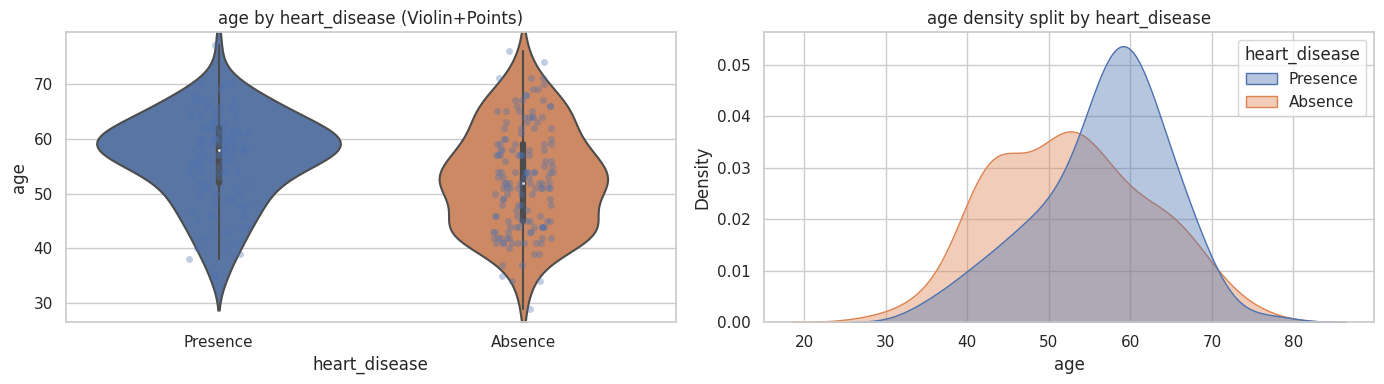

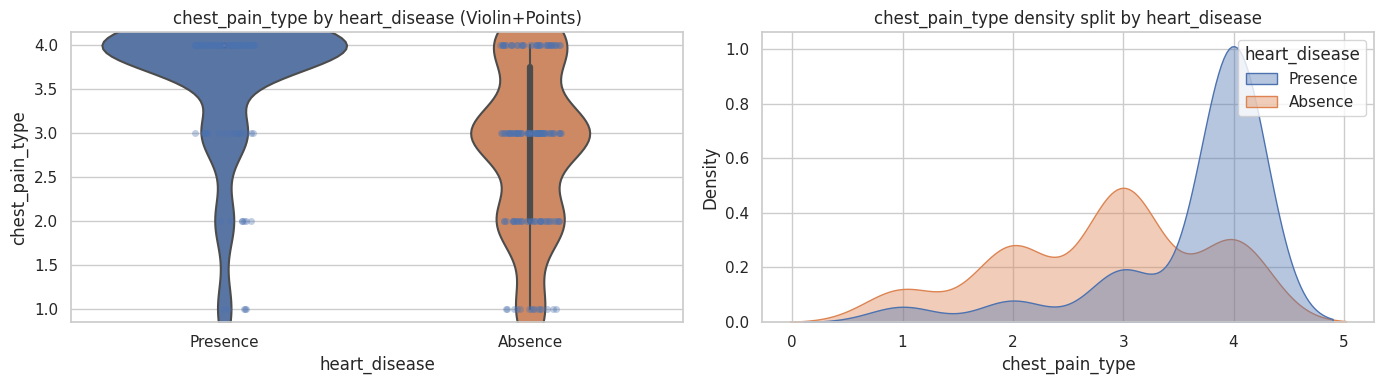

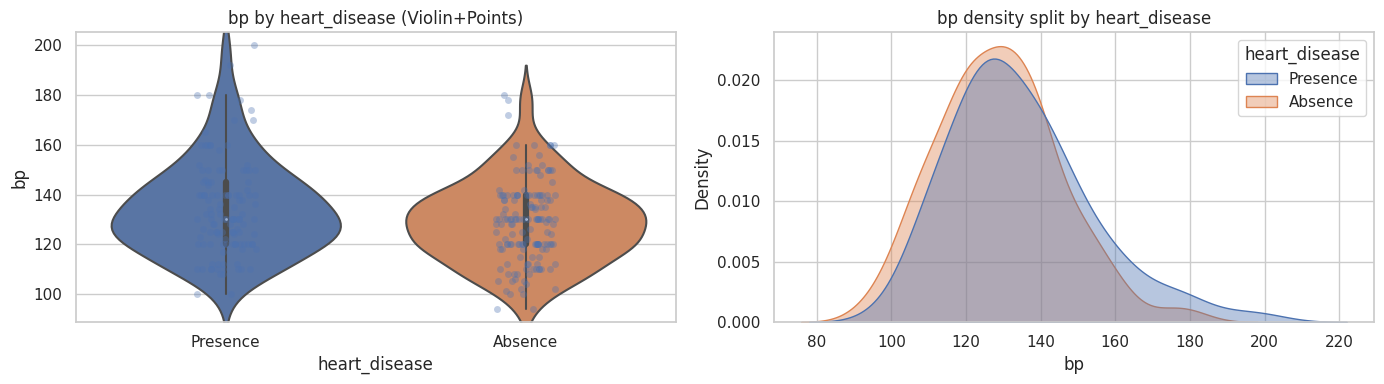

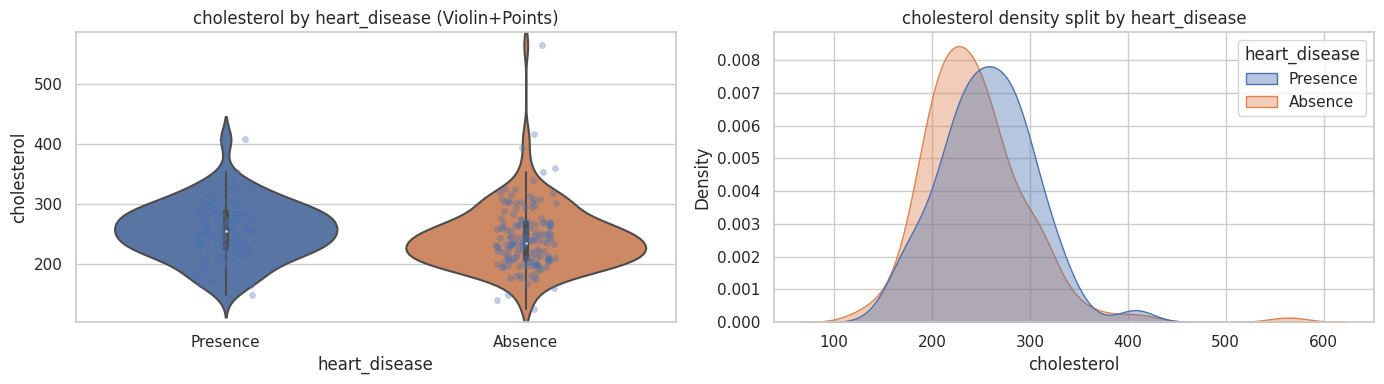

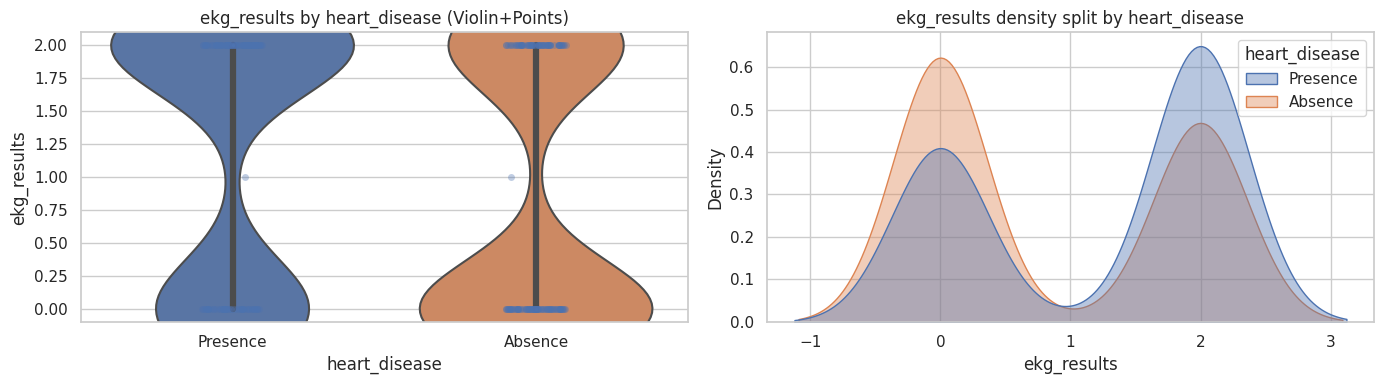

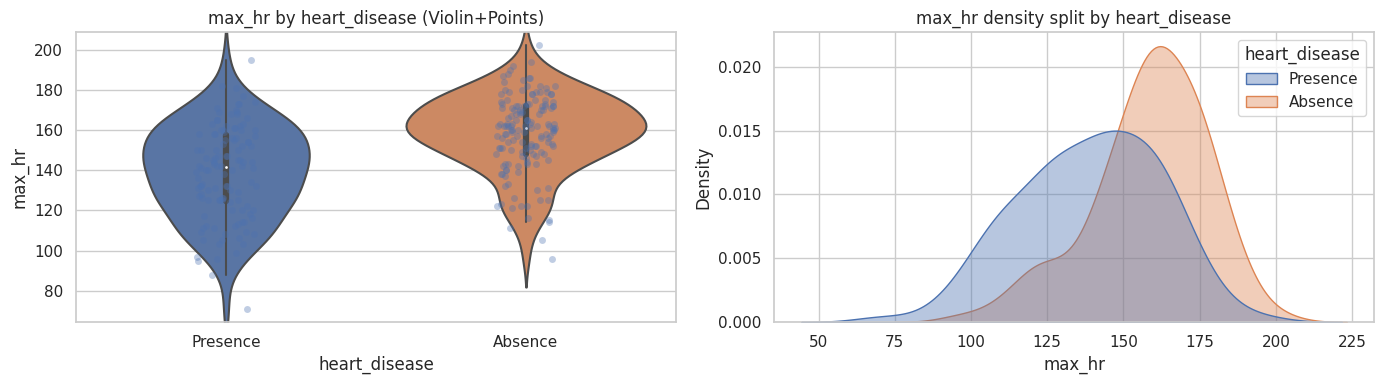

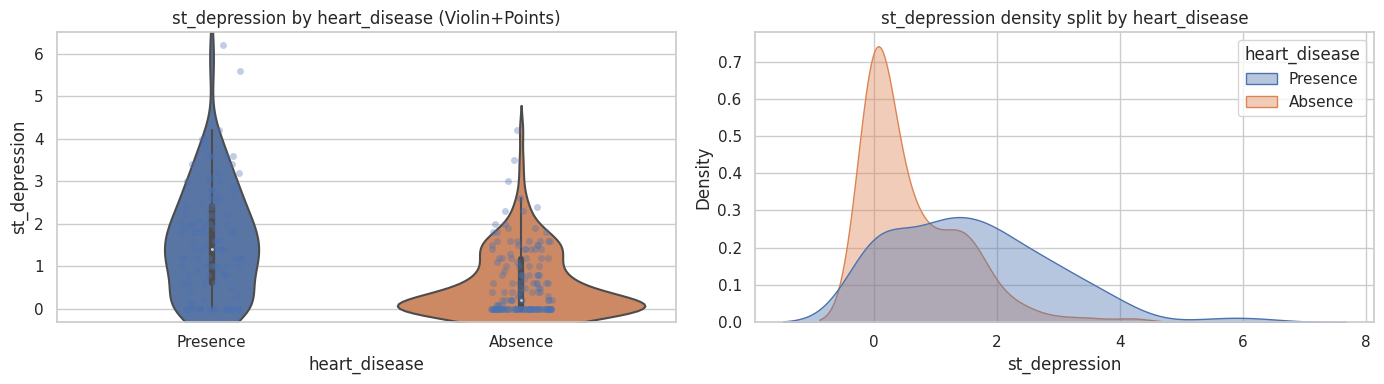

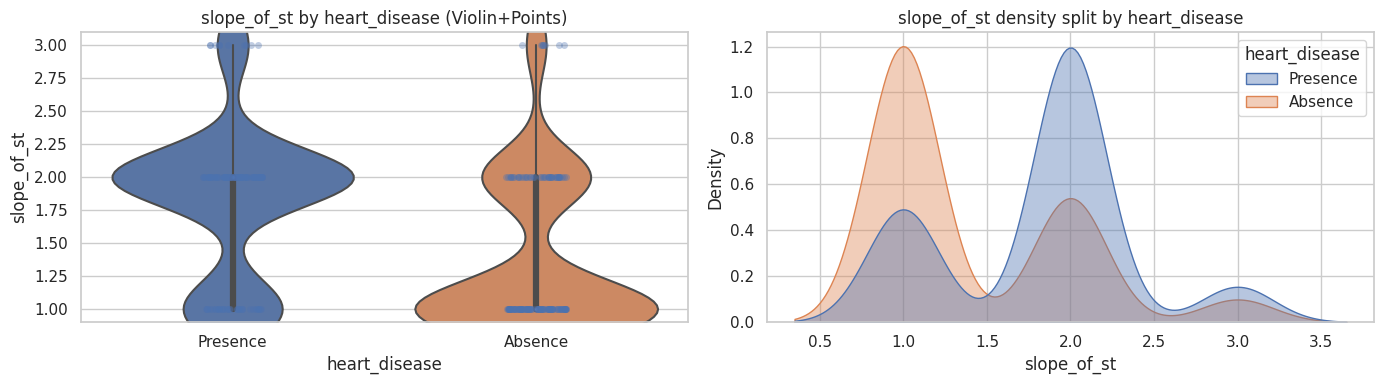

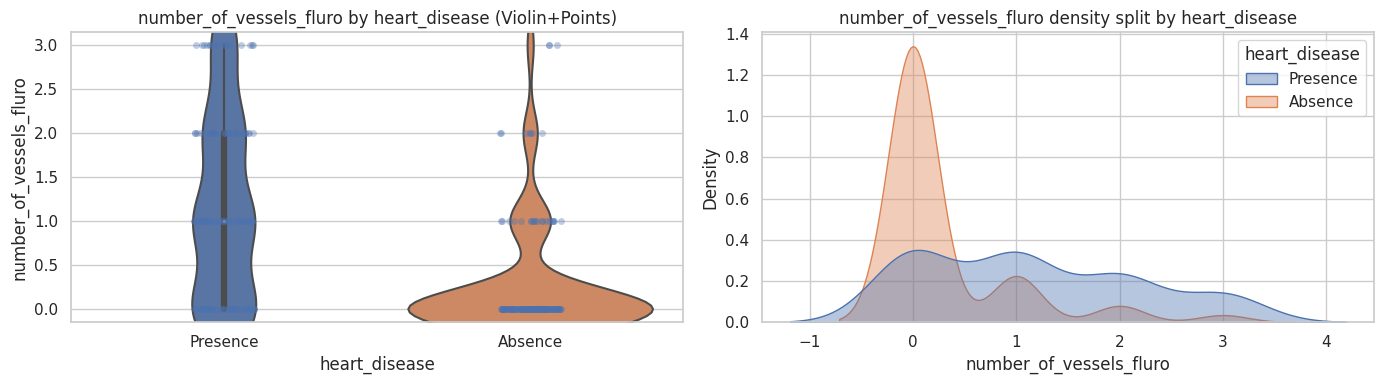

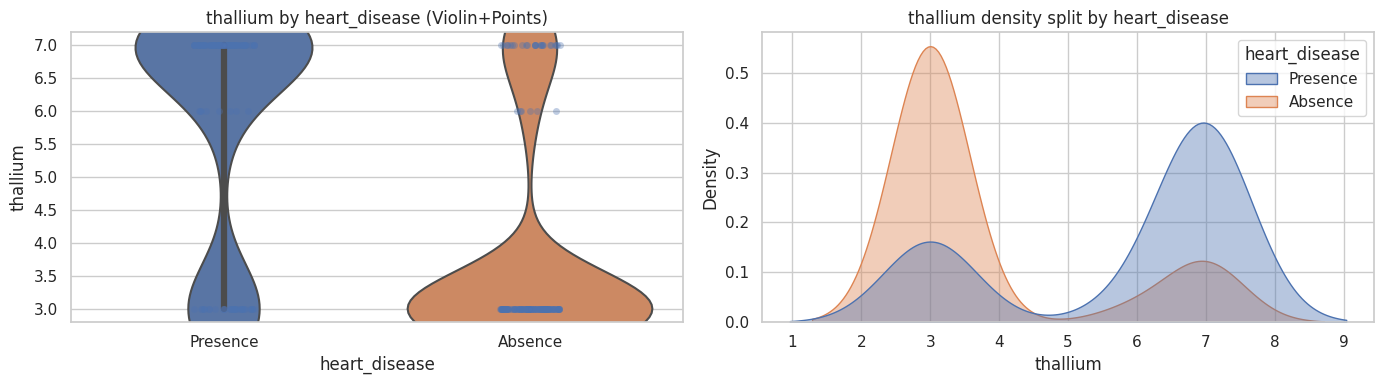

In [57]:
def plot_numeric_vs_target(df, col, target):
    tmp = df[[col, target]].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    sns.violinplot(data=tmp, x=target, y=col, inner="box", ax=axes[0])
    sns.stripplot(data=tmp, x=target, y=col, ax=axes[0], alpha=0.35)
    axes[0].set_title(f"{col} by {target} (Violin+Points)")
    
    sns.kdeplot(data=tmp, x=col, hue=target, common_norm=False, fill=True, alpha=0.4, ax=axes[1])
    axes[1].set_title(f"{col} density split by {target}")
    
    plt.tight_layout()
    plt.show()

for c in num_cols:
    plot_numeric_vs_target(df, c, target_col)


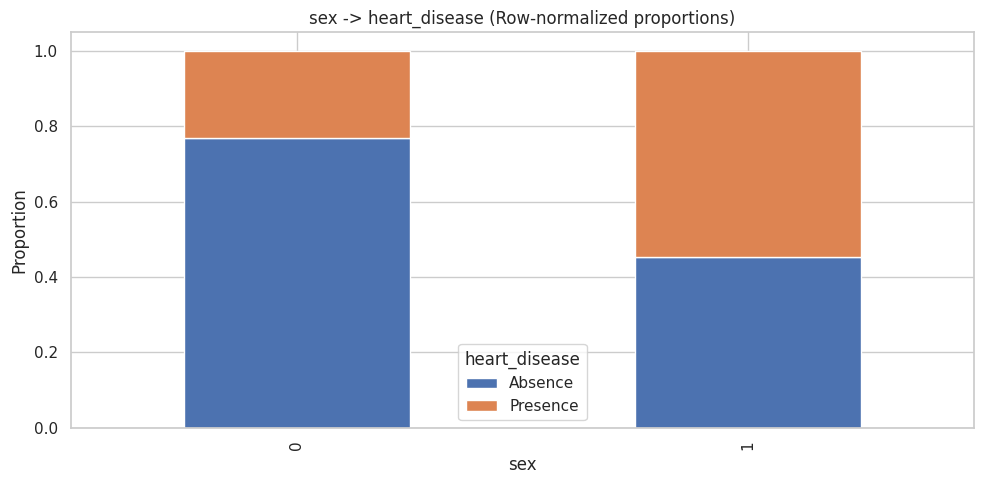

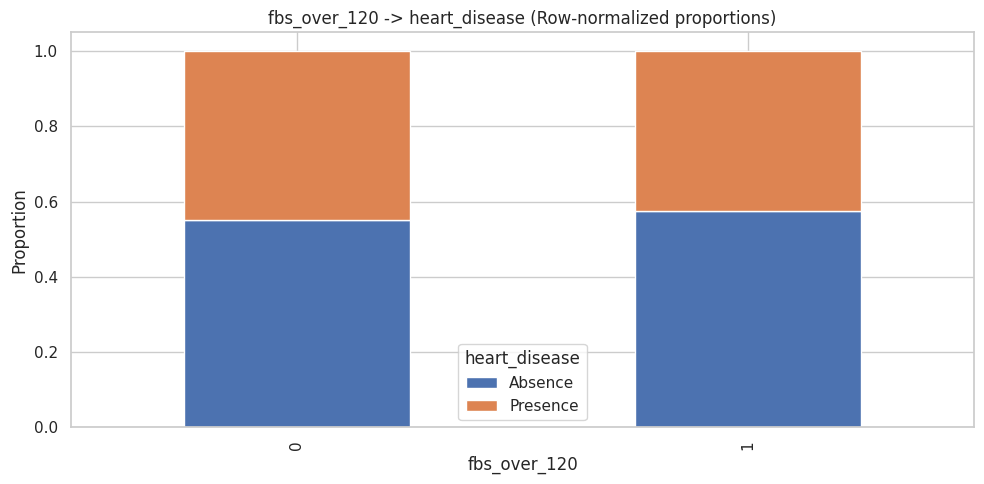

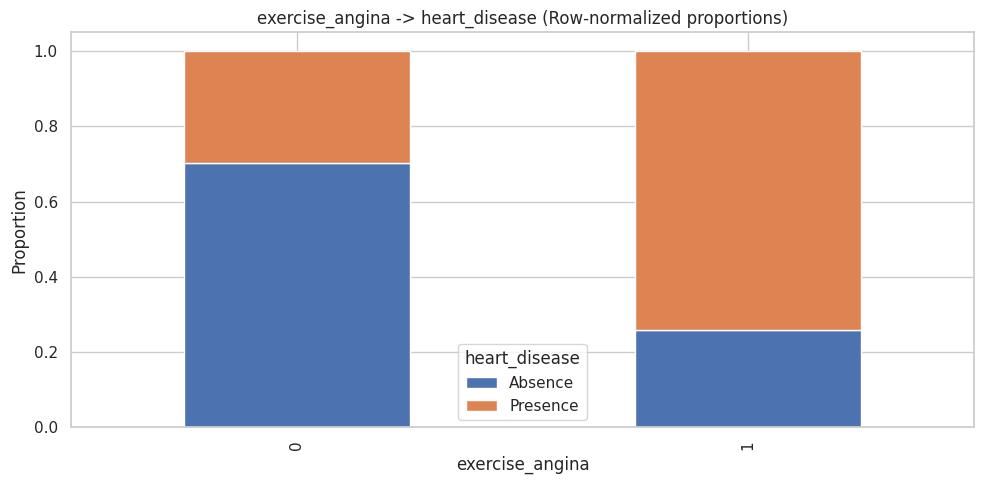

In [58]:
def plot_cat_vs_target(df, col, target):
    tmp = df[[col, target]].dropna()
    ct = pd.crosstab(tmp[col], tmp[target], normalize="index")
    ct.plot(kind="bar", stacked=True)
    plt.title(f"{col} -> {target} (Row-normalized proportions)")
    plt.ylabel("Proportion")
    plt.tight_layout()
    plt.show()

for c in cat_cols + bin_cols:
    plot_cat_vs_target(df, c, target_col)


# 7) Statistical Testing (Stop guessing)
## Numeric feature vs binary target

* If roughly normal: t-test
* If not: Mann–Whitney U
* Always include effect size:
    * Cohen’s d (mean separation)
    * Cliff’s delta (distribution separation, nonparametric)

## Categorical feature vs target
* Chi-square test
* Cramér’s V for strength (effect size)

We also apply multiple comparison correction (Benjamini–Hochberg), because otherwise you’ll “discover” fake significance.

In [59]:
def cohens_d(a, b):
    a, b = np.array(a), np.array(b)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    n1, n2 = len(a), len(b)
    s1, s2 = np.var(a, ddof=1), np.var(b, ddof=1)
    sp = np.sqrt(((n1-1)*s1 + (n2-1)*s2) / (n1+n2-2))
    return (np.mean(a) - np.mean(b)) / sp if sp != 0 else np.nan

def cliffs_delta(a, b):
    a, b = np.array(a), np.array(b)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    # O(n^2) but dataset is small; acceptable
    gt = sum(x > y for x in a for y in b)
    lt = sum(x < y for x in a for y in b)
    return (gt - lt) / (len(a)*len(b))

def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt((chi2/n) / (min(r-1, k-1))) if min(r-1, k-1) > 0 else np.nan

results = []

y = df[target_col]
group0 = df[y == 0]
group1 = df[y == 1]

# Numeric tests
for c in num_cols:
    a = group0[c].dropna()
    b = group1[c].dropna()
    if len(a) < 5 or len(b) < 5:
        continue
    
    # normality check (weak, but helps decide)
    p_norm_a = stats.shapiro(a.sample(min(len(a), 500), random_state=RANDOM_STATE))[1] if len(a) >= 3 else 0
    p_norm_b = stats.shapiro(b.sample(min(len(b), 500), random_state=RANDOM_STATE))[1] if len(b) >= 3 else 0
    normal = (p_norm_a > 0.05) and (p_norm_b > 0.05)
    
    if normal:
        p = stats.ttest_ind(a, b, equal_var=False).pvalue
        test = "t-test (Welch)"
    else:
        p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
        test = "Mann–Whitney U"
    
    results.append({
        "feature": c,
        "type": "numeric",
        "test": test,
        "p_value": p,
        "cohens_d": cohens_d(b, a),           # disease vs no disease direction
        "cliffs_delta": cliffs_delta(b, a)
    })

# Categorical tests
for c in cat_cols + bin_cols:
    tmp = df[[c, target_col]].dropna()
    if tmp[c].nunique() < 2:
        continue
    table = pd.crosstab(tmp[c], tmp[target_col])
    chi2, p, dof, exp = stats.chi2_contingency(table)
    results.append({
        "feature": c,
        "type": "categorical",
        "test": "chi-square",
        "p_value": p,
        "cramers_v": cramers_v(table)
    })

res = pd.DataFrame(results)

# BH correction
res = res.sort_values("p_value")
m = len(res)
res["p_adj_bh"] = res["p_value"] * m / (np.arange(1, m+1))
res["p_adj_bh"] = res["p_adj_bh"].clip(upper=1)

display(res)


,feature,type,test,p_value,cramers_v,p_adj_bh
2,exercise_angina,categorical,chi-square,1.383958e-11,0.411375,4.151874e-11
0,sex,categorical,chi-square,1.926226e-06,0.289746,2.889338e-06
1,fbs_over_120,categorical,chi-square,9.237061e-01,0.005828,9.237061e-01


# 8) Correlation + Association (Pearson/Spearman + Cramér’s V heatmaps)

* Pearson: linear numeric relationships
* Spearman: monotonic relationships (better under skew/outliers)
* Cramér’s V: categorical↔categorical association strength

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


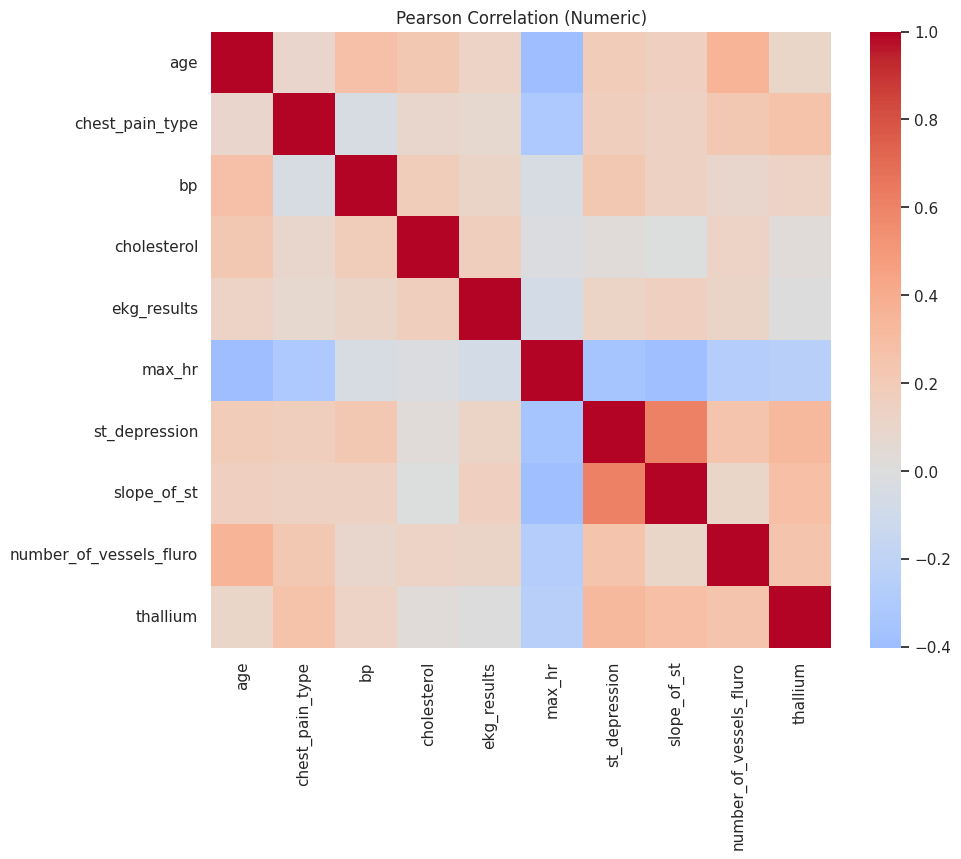

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


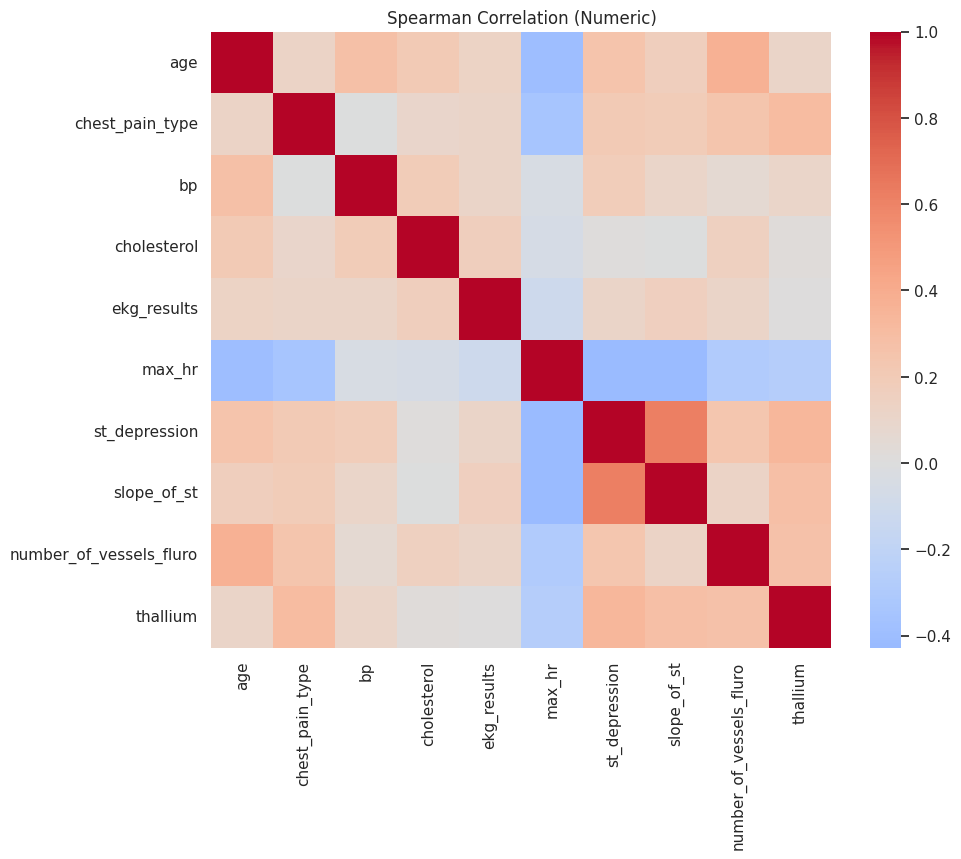

In [60]:
# Numeric correlations
if len(num_cols) > 1:
    pear = df[num_cols].corr(method="pearson")
    spear = df[num_cols].corr(method="spearman")

    plt.figure(figsize=(10, 8))
    sns.heatmap(pear, annot=False, cmap="coolwarm", center=0)
    plt.title("Pearson Correlation (Numeric)")
    plt.show()

    plt.figure(figsize=(10, 8))
    sns.heatmap(spear, annot=False, cmap="coolwarm", center=0)
    plt.title("Spearman Correlation (Numeric)")
    plt.show()


# 9) Multivariate Visuals (Where patterns hide)

### PCA (linear structure)
* Visualize separability in 2D after scaling
* Loadings tell you which features drive components

### t-SNE (nonlinear)
* Can reveal clusters, but can lie if you over-interpret distances
* We’ll do PCA + t-SNE.

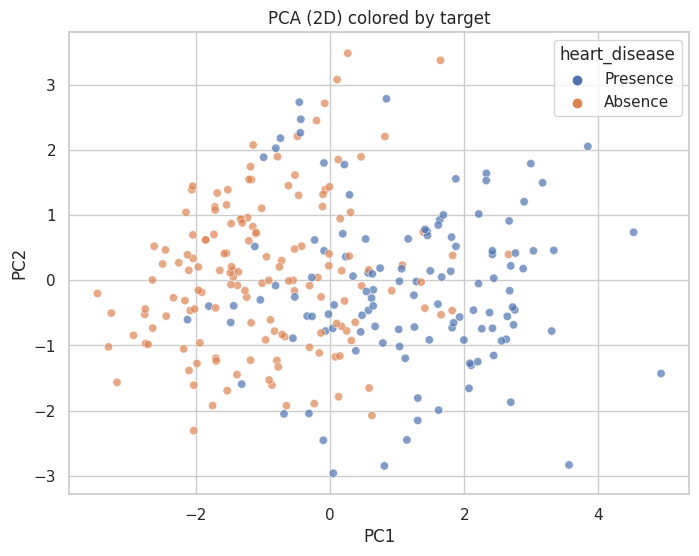

,pc1_loading
st_depression,0.429974
max_hr,-0.408803
slope_of_st,0.396208
age,0.339506
number_of_vessels_fluro,0.330138
thallium,0.328922
chest_pain_type,0.264912
bp,0.206944
ekg_results,0.168069
cholesterol,0.131623


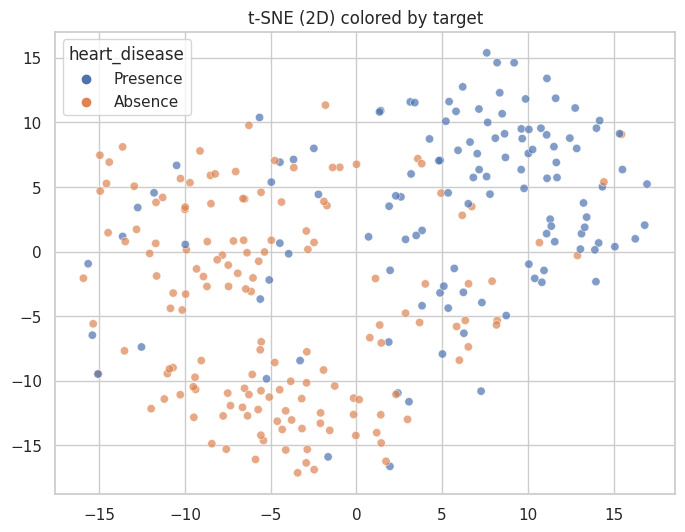

In [61]:
num_data = df[num_cols].copy()
num_data = num_data.fillna(num_data.median(numeric_only=True))

scaler = StandardScaler()
Z = scaler.fit_transform(num_data)

# PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=P[:,0], y=P[:,1], hue=df[target_col], alpha=0.7)
plt.title("PCA (2D) colored by target")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# PCA loadings
loadings = pd.Series(pca.components_[0], index=num_cols).sort_values(key=np.abs, ascending=False)
display(pd.DataFrame({"pc1_loading": loadings}))

# t-SNE (small datasets)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init="pca", learning_rate="auto")
T = tsne.fit_transform(Z)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=T[:,0], y=T[:,1], hue=df[target_col], alpha=0.7)
plt.title("t-SNE (2D) colored by target")
plt.show()


# 10) Baseline Model Visuals (So you know if this dataset is even useful)

This is not “modeling for ego.” This is dataset assessment:
* ROC curve (ranking ability)
* Precision-Recall (better under imbalance)
* Calibration curve (probabilities meaningful or garbage?)
* Threshold tradeoffs (pick decision threshold)

We use Logistic Regression because it’s interpretable and hard to cheat with.

In [62]:
from sklearn.calibration import calibration_curve

X = df[X_cols].copy()
y = df[target_col].astype(int)

# preprocess
numeric_features = [c for c in X_cols if c in num_cols]
categorical_features = [c for c in X_cols if c in cat_cols + bin_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", sm.imputation.mice.MICEData)]), [])  # placeholder, we'll not use statsmodels here
    ],
    remainder="drop"
)


ValueError: invalid literal for int() with base 10: 'Presence'

In [ ]:
from sklearn.impute import SimpleImputer

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features),
    ]
)

clf = LogisticRegression(max_iter=500, class_weight="balanced")

pipe = Pipeline(steps=[("preprocess", preprocess),
                      ("model", clf)])

# Cross-validated predicted probabilities (more honest than a single split)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]

roc_auc = roc_auc_score(y, proba)
ap = average_precision_score(y, proba)
brier = brier_score_loss(y, proba)

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Avg Precision (PR-AUC): {ap:.3f}")
print(f"Brier (lower better): {brier:.3f}")

# ROC
fpr, tpr, _ = roc_curve(y, proba)
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1], linestyle="--")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

# PR
prec, rec, _ = precision_recall_curve(y, proba)
plt.plot(rec, prec)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

# Calibration
frac_pos, mean_pred = calibration_curve(y, proba, n_bins=10)
plt.plot(mean_pred, frac_pos, marker="o")
plt.plot([0,1],[0,1], linestyle="--")
plt.title("Calibration Curve")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.show()


# 11) Interpretability Visuals (What features actually matter?)

### Logistic Coefficients (global, linear)
* Positive coef → increases predicted risk
* Negative coef → decreases predicted risk

### Permutation Importance (model-agnostic)
* Measures performance drop when feature is shuffled
* Harder to fool than raw coefficients

In [ ]:
pipe.fit(X, y)

# Get feature names after preprocessing
ohe = pipe.named_steps["preprocess"].named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_features)

feature_names = np.r_[numeric_features, cat_feature_names]
coefs = pipe.named_steps["model"].coef_.ravel()

coef_df = pd.DataFrame({"feature": feature_names, "coef": coefs})
coef_df["abs"] = coef_df["coef"].abs()
coef_df = coef_df.sort_values("abs", ascending=False).head(25)

plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df, y="feature", x="coef")
plt.title("Top Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

# Permutation importance (on full data; better: holdout set)
r = permutation_importance(pipe, X, y, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc")
imp = pd.DataFrame({"feature": X_cols, "importance": r.importances_mean}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp.head(15), y="feature", x="importance")
plt.title("Permutation Importance (ROC-AUC drop)")
plt.tight_layout()
plt.show()


# 12) Advanced Visualization Menu (Use the right tool, not all tools)
Here’s what each “complex” visualization is for:

### A) Distribution diagnostics
* QQ plot: Is normality assumption reasonable?
* ECDF: Shows full distribution; less misleading than KDE
* Rug plots: Adds discrete point density

### B) Group separation
* Violin + strip: distribution + raw points
* Ridge plot: shape shift across target groups
* Effect size plot: makes “difference” quantitative

### C) Association structure
* Spearman heatmap: robust numeric association
* Pairplot (small): detects nonlinear patterns quickly
* Parallel coordinates: multivariate separation (scaled features)

### D) Multivariate geometry
* PCA: linear structure + loadings
* t-SNE/UMAP: nonlinear cluster hints (don’t over-interpret)

### E) Model-quality assessment visuals
* ROC + PR: ranking quality
* Calibration: probability truthfulness
* Threshold curves: precision/recall tradeoff
* Lift/Gains: business-facing impact